# Tune `exp_bump_model` Parameters

$$\text{area} = a \cdot e^{(x+b)/c} \cdot \left(1 - e^{(x+b)/d}\right) + e$$

where $x$ = AFT.  Edit UPPER/LOWER in cell 2, re-run.  Check the Δ table to see fit at each guide point.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# ═══════════════════════════════════════════════════════════════
# TUNE THESE  (a, b, c, d, e)
#   c: more negative → bottom tilts rightwards  (main knob)
#   e: high-AFT asymptote
#   a: total swing (adjust so low-AFT area matches)
#   d: shoulder shape at low AFT
#   b: horizontal shift
# ═══════════════════════════════════════════════════════════════

UPPER = [8.86e4, -0.06, -0.09, -0.06, 69000]
LOWER = [7.30e4, -0.06, -0.09, -0.06, 59000]

# ── Known guide points  (area, AFT) ──
UPPER_PTS = np.array([
    [69000, 0.55],
    [71000, 0.40],
    [75000, 0.30],
    [84000, 0.20],
    [97000, 0.13],
])

LOWER_PTS = np.array([
    [59000, 0.55],
    [61000, 0.40],
    [65000, 0.30],
    [73000, 0.20],
    [82000, 0.13],
])

AREA_MIN, AREA_MAX = 20000, 100000
AFT_MIN, AFT_MAX = 0.10, 0.60

In [17]:
def exp_bump_model(x, a, b, c, d, e):
    return a * np.exp((x + b) / c) * (1 - np.exp((x + b) / d)) + e

aft_fine = np.linspace(AFT_MIN, AFT_MAX, 500)

def check(pars, pts, label):
    print(f"\n=== {label} ===")
    print(f"a={pars[0]:.2e}  b={pars[1]:.4f}  c={pars[2]:.4f}  d={pars[3]:.4f}  e={pars[4]:.0f}")
    for area_true, aft in pts:
        area_fit = exp_bump_model(aft, *pars)
        print(f"  AFT={aft:.2f}  target={area_true:.0f}  fit={area_fit:.0f}  Δ={area_fit-area_true:+.0f} PE")

check(UPPER, UPPER_PTS, "UPPER")
check(LOWER, LOWER_PTS, "LOWER")

print(f"\nBand widths:")
for aft in [0.13, 0.20, 0.30, 0.40, 0.55]:
    w = exp_bump_model(aft, *UPPER) - exp_bump_model(aft, *LOWER)
    print(f"  AFT={aft:.2f}  width={w:.0f} PE")


=== UPPER ===
a=8.86e+04  b=-0.0600  c=-0.0900  d=-0.0600  e=69000
  AFT=0.55  target=69000  fit=69383  Δ=+383 PE
  AFT=0.40  target=71000  fit=71020  Δ=+20 PE
  AFT=0.30  target=75000  fit=75043  Δ=+43 PE
  AFT=0.20  target=84000  fit=85888  Δ=+1888 PE
  AFT=0.13  target=97000  fit=97029  Δ=+29 PE

=== LOWER ===
a=7.30e+04  b=-0.0600  c=-0.0900  d=-0.0600  e=59000
  AFT=0.55  target=59000  fit=59315  Δ=+315 PE
  AFT=0.40  target=61000  fit=60664  Δ=-336 PE
  AFT=0.30  target=65000  fit=63979  Δ=-1021 PE
  AFT=0.20  target=73000  fit=72914  Δ=-86 PE
  AFT=0.13  target=82000  fit=82094  Δ=+94 PE

Band widths:
  AFT=0.13  width=14935 PE
  AFT=0.20  width=12973 PE
  AFT=0.30  width=11064 PE
  AFT=0.40  width=10356 PE
  AFT=0.55  width=10067 PE


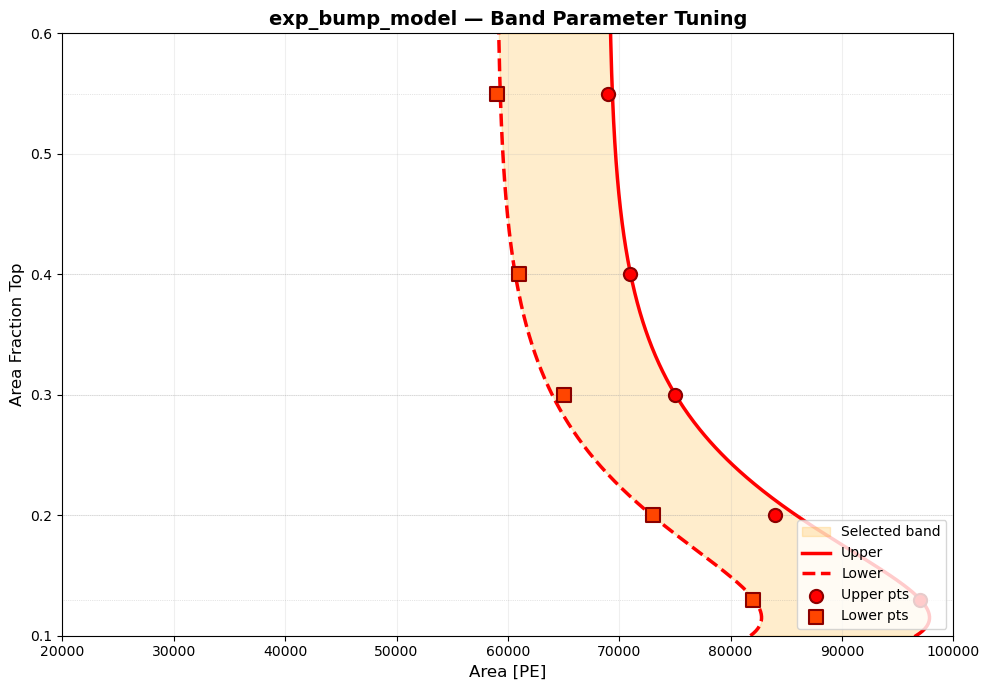

In [18]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.fill_betweenx(aft_fine,
                 exp_bump_model(aft_fine, *LOWER),
                 exp_bump_model(aft_fine, *UPPER),
                 alpha=0.20, color='orange', label='Selected band')

ax.plot(exp_bump_model(aft_fine, *UPPER), aft_fine, 'r-', lw=2.5, label='Upper')
ax.plot(exp_bump_model(aft_fine, *LOWER), aft_fine, 'r--', lw=2.5, label='Lower')

ax.scatter(UPPER_PTS[:,0], UPPER_PTS[:,1], c='red', s=90, zorder=5,
           edgecolors='darkred', linewidths=1.5, label='Upper pts')
ax.scatter(LOWER_PTS[:,0], LOWER_PTS[:,1], c='orangered', s=90, zorder=5,
           edgecolors='darkred', linewidths=1.5, marker='s', label='Lower pts')

for aft_ref in [0.13, 0.20, 0.30, 0.40, 0.55]:
    ax.axhline(y=aft_ref, color='gray', ls=':', lw=0.5, alpha=0.4)

ax.set_xlim(AREA_MIN, AREA_MAX)
ax.set_ylim(AFT_MIN, AFT_MAX)
ax.set_xlabel('Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('exp_bump_model — Band Parameter Tuning', fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='lower right')
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

In [19]:
print(f"rn_upper_pars = [{UPPER[0]:.2e}, {UPPER[1]:.4f}, {UPPER[2]:.4f}, {UPPER[3]:.4f}, {UPPER[4]:.0f}]")
print(f"rn_lower_pars = [{LOWER[0]:.2e}, {LOWER[1]:.4f}, {LOWER[2]:.4f}, {LOWER[3]:.4f}, {LOWER[4]:.0f}]")

rn_upper_pars = [8.86e+04, -0.0600, -0.0900, -0.0600, 69000]
rn_lower_pars = [7.30e+04, -0.0600, -0.0900, -0.0600, 59000]


## Tuning guide

| Knob | Does | Direction |
|------|------|-----------|
| **`e`** | High-AFT asymptote | Set = area at AFT≈0.55 |
| **`c`** | Tilt | More negative → low-AFT end goes right |
| **`a`** | Overall stretch | Increase → low-AFT area goes up |
| **`d`** | Low-AFT knee | More negative → sharper knee |
| **`b`** | Shift left/right | More negative → curve moves right at low AFT |

1. Set `e` ≈ area at highest AFT point
2. Tune `c` for tilt (low AFT area relative to high)
3. Scale `a` to match lowest AFT point
4. Tweak `d`, `b` to fix intermediate points
5. For lower band: same a,b,c,d, adjust `e` then `a`